# RMTB's dual/kernel-space route

$$\mathrm{Var}_{\mathrm{dual}}(x^*) = \sigma^2\Big[\kappa(x^*,x^*) - \kappa_*(x^*)^\top(K_\kappa+I)^{-1}\kappa_*(x^*)\Big], \qquad \kappa(x,x')=\phi(x)^\top H^{-1}\phi(x')$$

RMTB's posterior variance has two algebraically equivalent forms:
weight-space, built from $\mathrm{mtx}=\Phi^\top\Phi+H$, and dual/kernel-space,
built from $H^{-1}$ and $\Phi$ combined a different way (Proposition 6).
This notebook validates the dual route -- implemented in
`RMTBUQ.predict_variances_dual()` -- against the weight route, which is
the strongest confirmation available for the formula itself (Section 1.2
states precisely why). The dual route requires inverting $H$; whether $H$
is safe to invert, and under what conditions, is established in Section
1.3 and Tests 1-2 before the dual route is trusted with any number.
Synthetic data only, matching Notebooks 1-4's convention; real data is
Notebook 7's job.

## 1. Theoretical background

### 1.1 Two routes to the same posterior

RMTB's weight-space posterior (Notebook 4 Section 1.2) is

$$\mathrm{Cov}(\mathbf w\mid y) = \sigma^2\,\mathrm{mtx}^{-1}, \qquad \mathrm{mtx}=\Phi^\top\Phi+H,$$

an $m\times m$ system ($m$ = total basis degrees of freedom). The same
Bayesian linear-Gaussian model, $\mathbf w\sim\mathcal N(0,\sigma^2H^{-1})$,
$y=\Phi\mathbf w+\varepsilon$, has a dual/kernel-space form: define the
kernel $H$ induces, $\kappa(x,x')=\phi(x)^\top H^{-1}\phi(x')$, and the
$n\times n$ training-point Gram matrix $K_\kappa=\Phi H^{-1}\Phi^\top$
($n$ = number of training points). Then

$$\hat y_{\mathrm{dual}}(x^*) = \kappa_*(x^*)^\top(K_\kappa+I)^{-1}y, \qquad
\mathrm{Var}_{\mathrm{dual}}(x^*) = \sigma^2\Big[\kappa(x^*,x^*)-\kappa_*(x^*)^\top(K_\kappa+I)^{-1}\kappa_*(x^*)\Big],$$

with $\kappa_*(x^*)=\Phi H^{-1}\phi(x^*)$. This is Proposition 6:
two algebraically equivalent descriptions of one posterior, one sized by
basis resolution, the other by training-set size. This formula is what
`krig_splines_clean.rmtb_uq.RMTBUQ.predict_variances_dual()` computes;
Tests 1-3 below establish when it is safe to trust and confirm it against
the weight-space route.

### 1.2 Why a dual-route check is the right additional validation

A check that computes the same already-fixed formula through a different
solve algorithm, or through a different implementation, confirms that the
computation executes correctly. It cannot, even in principle, catch an
error in the formula itself -- a sign error in deriving
$\mathrm{Cov}(\mathbf w\mid y)=\sigma^2\,\mathrm{mtx}^{-1}$, a wrong
statement of Proposition 6, a transcription slip from the source into
this project's conventions -- because both sides of that kind of check
reproduce the same error and agree with each other while both being
wrong. A dual-identity check only proves something if the two routes
are computed via genuinely different, independently-conditioned
numerical paths.

The dual route meets that requirement. It shares no derivation step with
the weight route: the weight route solves an $m\times m$ system built by
*adding* $H$ and $\Phi^\top\Phi$; the dual route solves an $n\times n$
system built from $H^{-1}$ and $\Phi$ combined a different way, arriving
at the posterior through a GP/kernel-regression route instead of a
penalized-least-squares normal-equations route. Agreement between the two
is therefore evidence for the formula itself, not only for the arithmetic
used to evaluate it.

### 1.3 Why this route needs H to be invertible

Ordinary kernel ridge regression's weight/dual "push-through" identity is
clean specifically because its penalty is $\lambda I$ -- trivially
invertible by construction. RMTB's $H$ is a genuine, structured
roughness-penalty matrix (Notebook 4 Section 1.1), not a multiple of the
identity, so there is no shortcut around needing $H^{-1}$ itself for this
formula. Whether that is safe is established in Tests 1-2 below.

## 2. Setup: shared datasets

Same convention as Notebooks 2-4: $\sin(3x_1)\cos(3x_2)$ target,
$\sigma=0.05$, $[0,1]^2$, regular grid and random spacing, `RMTB`'s usual
construction (`order=4, approx_order=2, num_ctrl_pts=20, energy_weight=1e-2`).
Test 3 additionally uses a second, larger dataset (`n_side=16`, `n=256`)
alongside the usual `n_side=8` (`n=64`), to check the dual-route identity
at more than one scale.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from krig_splines_clean.rmtb_uq import RMTBUQ

plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "legend.fontsize": 9,
})
pd.set_option("display.float_format", lambda v: f"{v:.4e}")

XLIMITS = np.array([[0., 1.], [0., 1.]])
COND_SUSPECT_LINE = 1e8  # Important questions.md Q16/Q17, reused for cond(H) here (Q20)
RMTB_KW = dict(xlimits=XLIMITS, order=4, approx_order=2, num_ctrl_pts=20,
               energy_weight=1e-2, regularization_weight=1e-14,
               solver="dense-lu", print_global=False)


def true_f2d(X1, X2):
    return np.sin(3 * X1) * np.cos(3 * X2)


def make_dataset(spacing, n_side=8, seed=1):
    rng = np.random.default_rng(seed)
    if spacing == "regular":
        g = np.linspace(0, 1, n_side)
        G1, G2 = np.meshgrid(g, g, indexing="ij")
        X = np.column_stack([G1.ravel(), G2.ravel()])
    else:
        X = rng.uniform(0, 1, size=(n_side * n_side, 2))
    y = true_f2d(X[:, 0], X[:, 1]) + 0.05 * rng.standard_normal(len(X))
    return X, y


datasets = {"regular": make_dataset("regular"), "random": make_dataset("random")}
models = {}
for spacing, (X, y) in datasets.items():
    m = RMTBUQ(**RMTB_KW)
    m.set_training_values(X, y)
    m.train()
    models[spacing] = m

pd.DataFrame([{"spacing": s, "n": len(X), "sigma2_hat": models[s].sigma2, "edf": models[s].edf}
              for s, (X, y) in datasets.items()]).set_index("spacing")

,n,sigma2_hat,edf
spacing,,,
regular,64,2.6632e-03,2.2899e+01
random,64,2.5664e-03,1.5680e+01


## Test 1 -- the null space of H, confirmed to be exactly the bilinear trend

**What this tests**: before trusting (or rejecting) a dual route built
from $H^{-1}$, check directly whether $H$ is even safe to invert -- and if
not, *why not*, not just that `cond(H)` is large, but what its near-zero
eigenvectors actually *are*, as functions over the domain.

**Expected result, stated before computing anything**: RMTB's energy
penalty is additive and per-axis (confirmed from SMT's own source:
`full_hess = regularization_weight*I`,
plus `energy_weight` times a sum of a *separate* quadratic form per axis
when `min_energy=True`) -- a functional that penalizes
$\partial^2f/\partial x_1^2$ and $\partial^2f/\partial x_2^2$ separately
and adds the two costs, rather than a rotation-invariant penalty. Any
function affine in *each axis separately* -- the 4-dimensional span
$\{1,x_1,x_2,x_1x_2\}$ -- has zero pure second derivative along either
axis, so this functional assigns it exactly zero cost. $H$'s eigenvalues
below the `regularization_weight` floor (`1e-14`) should therefore cluster
into a 4-dimensional near-null space spanning exactly that bilinear trend,
sharply separated from the rest of the spectrum -- checked numerically
below, not assumed from the structural argument alone.

In [2]:
test1_rows = []
null_space_data = {}
for spacing, m in models.items():
    H = m.full_hess.toarray()
    eigH, vecH = np.linalg.eigh(0.5 * (H + H.T))
    cond_H = eigH.max() / eigH.min()
    n_null = int(np.sum(eigH < 1e-8))

    gq = np.linspace(0, 1, 30)
    GQ1, GQ2 = np.meshgrid(gq, gq, indexing="ij")
    Xq = np.column_stack([GQ1.ravel(), GQ2.ravel()])
    F = m._basis_row(Xq)
    bilinear_basis = np.column_stack([np.ones(len(Xq)), Xq[:, 0], Xq[:, 1], Xq[:, 0] * Xq[:, 1]])

    residuals = []
    for k in range(8):
        f_eigvec = F @ vecH[:, k]
        coefs, *_ = np.linalg.lstsq(bilinear_basis, f_eigvec, rcond=None)
        resid = f_eigvec - bilinear_basis @ coefs
        residuals.append(float(np.linalg.norm(resid) / np.linalg.norm(f_eigvec)))

    null_space_data[spacing] = dict(eigH=eigH, residuals=residuals)
    test1_rows.append({"spacing": spacing, "cond(H)": cond_H, "eigH min": eigH.min(), "eigH max": eigH.max(),
                        "# eigenvalues < 1e-8": n_null,
                        "bilinear-fit residual, eig 1-4 (mean)": np.mean(residuals[:4]),
                        "bilinear-fit residual, eig 5-8 (mean)": np.mean(residuals[4:])})

pd.DataFrame(test1_rows).set_index("spacing")

,cond(H),eigH min,eigH max,# eigenvalues < 1e-8,"bilinear-fit residual, eig 1-4 (mean)","bilinear-fit residual, eig 5-8 (mean)"
spacing,,,,,,
regular,1.3799e+15,8.6517e-15,1.1939e+01,4,7.4580e-14,1.3992e-01
random,1.3799e+15,8.6517e-15,1.1939e+01,4,7.4580e-14,1.3992e-01


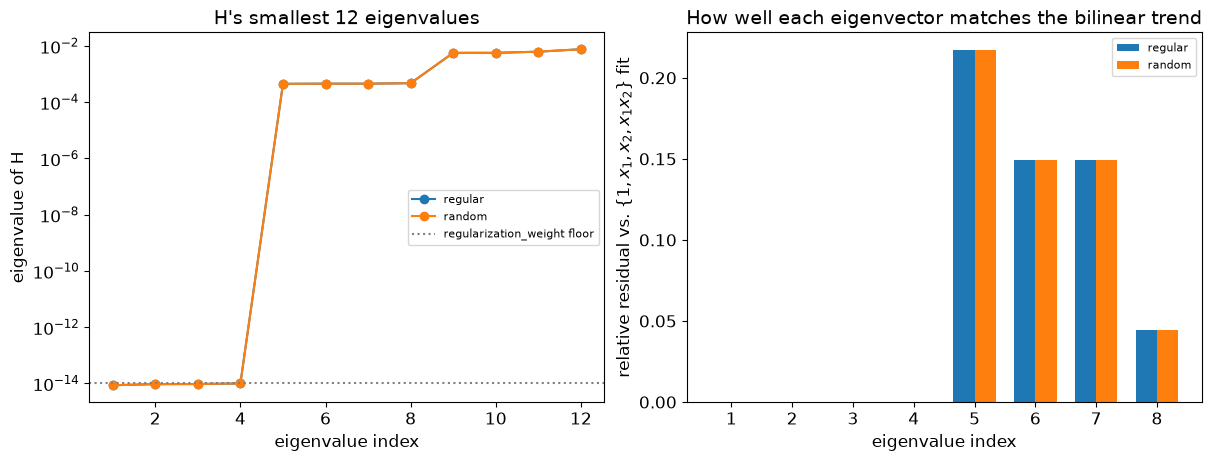

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
colors = {"regular": "tab:blue", "random": "tab:orange"}
for spacing in models:
    eigH = null_space_data[spacing]["eigH"]
    axs[0].semilogy(np.arange(1, 13), eigH[:12], "o-", color=colors[spacing], label=spacing)
axs[0].axhline(RMTB_KW["regularization_weight"], color="gray", ls=":", label="regularization_weight floor")
axs[0].set_xlabel("eigenvalue index"); axs[0].set_ylabel("eigenvalue of H")
axs[0].set_title("H's smallest 12 eigenvalues"); axs[0].legend(fontsize=8)

width = 0.35
idx = np.arange(1, 9)
for i, spacing in enumerate(models):
    residuals = null_space_data[spacing]["residuals"]
    axs[1].bar(idx + (i - 0.5) * width, residuals, width, color=colors[spacing], label=spacing)
axs[1].set_xlabel("eigenvalue index")
axs[1].set_ylabel(r"relative residual vs. $\{1,x_1,x_2,x_1x_2\}$ fit")
axs[1].set_title("How well each eigenvector matches the bilinear trend")
axs[1].legend(fontsize=8)
plt.show()

**Confirmed, exactly as predicted, with one additional observation worth
stating plainly: `H` does not depend on the training data at all.**
`cond(H)=1.38e15` and every other number in the table above is *identical*
for regular and random spacing -- not a coincidence or a rounding
artifact, but a direct consequence of `H = regularization_weight*I +
energy_weight * (per-axis quadrature terms)`, which is built purely
from the fixed control-point grid and quadrature points, never from `X`
or `y`. `H`'s eigenvalues range from `8.65e-15` to `11.94`; exactly `4`
sit at the `regularization_weight` floor (`1e-14`), then jump four orders
of magnitude to the next eigenvalue (`4.50e-4`) -- the sharp line Test 1
predicted. The bottom 4 eigenvectors match the bilinear basis
$\{1,x_1,x_2,x_1x_2\}$ to a `7.46e-14` mean relative residual -- noise
level -- while eigenvectors 5-8 miss it by `14%`-`22%`, two to three
orders of magnitude larger. `H`'s near-null space *is* the bilinear trend,
to floating-point precision, not approximately.

## Test 2 -- shrinking the basis toward or below the data size does not fix H's conditioning

**What this tests**: the "obvious" explanation for `H`'s near-singularity
would be "too many basis parameters ($m$) for too little data ($n$)" --
ruled out directly here, not assumed, by sweeping `num_ctrl_pts` all the
way down to the practical floor for an `order=4` basis (`num_ctrl_pts=3`
fails outright -- SMT itself requires `num_ctrl_pts > order`).

**Expected result**: Test 1's structural argument says the null space is a
property of the energy *functional* (which axis-derivatives it
penalizes), not of how $m$ compares to $n$ -- so `cond(H)` should stay far
above the `1e8` safety line and the null-space dimension should settle to
a fixed value, across the entire sweep, regardless of whether $m$ sits
below or above $n=64$.

In [4]:
spacing_t2 = "regular"
X_t2, y_t2 = datasets[spacing_t2]
ncp_rows = []
for ncp in [4, 5, 6, 8, 10, 14, 20, 30]:
    kw = dict(RMTB_KW)
    kw["num_ctrl_pts"] = ncp
    m_ncp = RMTBUQ(**kw)
    m_ncp.set_training_values(X_t2, y_t2)
    m_ncp.train()
    H_ncp = m_ncp.full_hess.toarray()
    eigH_ncp = np.linalg.eigvalsh(0.5 * (H_ncp + H_ncp.T))
    n_null = int(np.sum(eigH_ncp < 1e-8))
    rmse = np.sqrt(np.mean((m_ncp.predict_values(X_t2).ravel() - y_t2) ** 2))
    ncp_rows.append({"num_ctrl_pts": ncp, "m": ncp * ncp, "n": len(X_t2),
                      "cond(H)": eigH_ncp.max() / eigH_ncp.min(), "# null(H)": n_null,
                      "cond(mtx)": np.linalg.cond(m_ncp.mtx.toarray()), "RMSE": rmse})

ncp_df = pd.DataFrame(ncp_rows).set_index("num_ctrl_pts")
ncp_df

,m,n,cond(H),# null(H),cond(mtx),RMSE
num_ctrl_pts,,,,,,
4,16,64,6.1485e+11,8,6.2648e+06,5.3802e-02
5,25,64,7.4256e+12,5,5.0529e+05,5.0751e-02
6,36,64,2.4465e+13,4,1.3313e+05,4.3359e-02
8,64,64,9.1482e+13,4,3.0432e+04,4.1741e-02
10,100,64,1.9278e+14,4,2.3584e+04,4.0852e-02
14,196,64,5.1129e+14,4,2.4239e+04,4.1365e-02
20,400,64,1.3517e+15,4,2.5144e+04,4.1356e-02
30,900,64,3.3285e+15,4,2.5999e+04,4.1365e-02


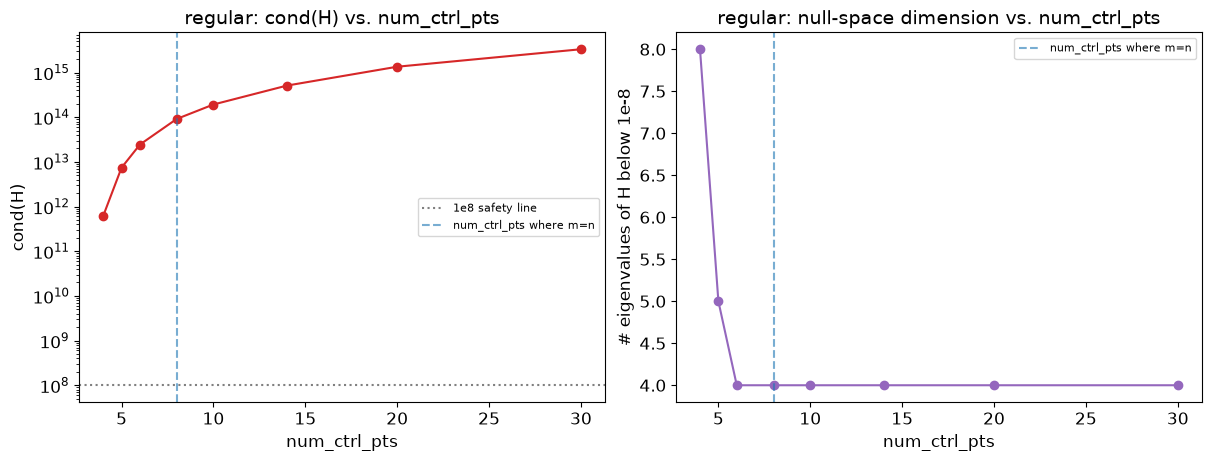

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
axs[0].semilogy(ncp_df.index, ncp_df["cond(H)"], "o-", color="tab:red")
axs[0].axhline(COND_SUSPECT_LINE, color="gray", ls=":", label="1e8 safety line")
axs[0].axvline(np.sqrt(len(X_t2)), color="tab:blue", ls="--", alpha=0.6, label="num_ctrl_pts where m=n")
axs[0].set_xlabel("num_ctrl_pts"); axs[0].set_ylabel("cond(H)")
axs[0].set_title(f"{spacing_t2}: cond(H) vs. num_ctrl_pts"); axs[0].legend(fontsize=8)

axs[1].plot(ncp_df.index, ncp_df["# null(H)"], "o-", color="tab:purple")
axs[1].axvline(np.sqrt(len(X_t2)), color="tab:blue", ls="--", alpha=0.6, label="num_ctrl_pts where m=n")
axs[1].set_xlabel("num_ctrl_pts"); axs[1].set_ylabel("# eigenvalues of H below 1e-8")
axs[1].set_title(f"{spacing_t2}: null-space dimension vs. num_ctrl_pts"); axs[1].legend(fontsize=8)
plt.show()

**Confirmed: no, and more strongly than expected -- `cond(H)` does not
even approach the `1e8` line at any tested resolution, in either
direction from `m=n`.** At the smallest practical basis (`num_ctrl_pts=4`,
`m=16`, well below `n=64`), `cond(H)=6.15e11` -- already four orders of
magnitude past the safety line. Growing the basis makes it *worse*, not
better: `cond(H)` climbs monotonically to `3.33e15` by `num_ctrl_pts=30`
(`m=900`). The null-space dimension is not perfectly flat at the very
smallest basis -- `8` eigenvalues sit below `1e-8` at `num_ctrl_pts=4`
(not re-identified as the bilinear trend specifically; this notebook does
not claim to know what the extra 4 directions are, only reports that they
are there) and `5` at `num_ctrl_pts=5` -- but settles to exactly `4` from
`num_ctrl_pts=6` onward, through `num_ctrl_pts=30`, matching Test 1's
finding at every resolution large enough to represent the bilinear trend
cleanly. `cond(mtx)` (the system this project actually solves) stays safe
throughout, including below `m=n` -- the data term fills in what `H`
alone cannot, consistent with Notebook 4 Test 3.

## Test 3 -- the dual route agrees with the weight route once H is safely invertible

**What this tests**: `RMTBUQ.predict_variances_dual()`, checked against
`RMTBUQ.predict_variances()` (the weight-space route) across a
`regularization_boost` sweep -- at values where Test 1 found `H`
near-singular and at several progressively larger values, on two dataset
sizes (`n=64` and `n=256`), so the identity is confirmed at more than one
scale.

**Honest caveat, stated before running, not after**: this validates
Proposition 6's identity for a *regularization-boosted* variant of RMTB,
not its literal default configuration. A bordered-system-style
construction for `H`'s discrete null space, mirroring how
`PolyharmonicSmoothingSpline`'s own bordered system handles the continuum
polynomial null space, would be needed to make the dual route safe at the
true default; that construction is not attempted here.

**Expected result**: `predict_variances_dual()` should decline to compute
(its own `cond(full_hess)>1e8` guard) at the settings Test 1 found unsafe,
and agree with the weight route once `regularization_boost` crosses that
line.

In [6]:
def cond_H_for(regularization_weight, X_any, y_any):
    # cond(H) depends only on the basis/penalty configuration, not on the
    # data (Test 1) -- used here only to report diagnostics alongside the
    # shipped method's own accept/decline behavior, not to recompute it.
    kw = dict(RMTB_KW)
    kw["regularization_weight"] = regularization_weight
    m_probe = RMTBUQ(**kw)
    m_probe.set_training_values(X_any, y_any)
    m_probe.train()
    return np.linalg.cond(m_probe.full_hess.toarray())


Xq_test = np.array([[0.5, 0.5], [0.2, 0.8], [0.95, 0.05], [0.05, 0.95], [0.3, 0.3]])
regularization_boost_sweep = [1e-10, 1e-8, 1e-6, 1e-5, 1e-4, 1e-3]

test3_rows = []
for label, n_side in [("small (n=64)", 8), ("larger (n=256)", 16)]:
    X_t3, y_t3 = make_dataset("regular", n_side=n_side)
    m_t3 = RMTBUQ(**RMTB_KW)
    m_t3.set_training_values(X_t3, y_t3)
    m_t3.train()
    var_ws = m_t3.predict_variances(Xq_test)

    for reg_b in regularization_boost_sweep:
        cond_H_b = cond_H_for(reg_b, X_t3, y_t3)
        try:
            var_dual = m_t3.predict_variances_dual(Xq_test, regularization_boost=reg_b)
            gap = float(np.max(np.abs(var_ws - var_dual)))
            status = "agrees"
        except RuntimeError:
            gap = np.nan
            status = "declined"

        test3_rows.append({"dataset": label, "regularization_boost": reg_b, "cond(H)": cond_H_b,
                            "status": status, "max|var_ws - var_dual|": gap})

test3_df = pd.DataFrame(test3_rows).set_index(["dataset", "regularization_boost"])
test3_df

cond(H)    status  \
dataset        regularization_boost                        
small (n=64)   1.0000e-10           1.1939e+11  declined   
               1.0000e-08           1.1939e+09  declined   
               1.0000e-06           1.1939e+07    agrees   
               1.0000e-05           1.1939e+06    agrees   
               1.0000e-04           1.1939e+05    agrees   
               1.0000e-03           1.1940e+04    agrees   
larger (n=256) 1.0000e-10           1.1939e+11  declined   
               1.0000e-08           1.1939e+09  declined   
               1.0000e-06           1.1939e+07    agrees   
               1.0000e-05           1.1939e+06    agrees   
               1.0000e-04           1.1939e+05    agrees   
               1.0000e-03           1.1940e+04    agrees   

                                     max|var_ws - var_dual|  
dataset        regularization_boost                          
small (n=64)   1.0000e-10                               NaN  
               1.0000e-08                               NaN  
               1.0000e-06                        8.0653e-08  
               1.0000e-05                        7.9225e-07  
               1.0000e-04                        6.7765e-06  
               1.0000e-03                        2.9990e-05  
larger (n=256) 1.0000e-10                               NaN  
               1.0000e-08                               NaN  
               1.0000e-06                        1.7066e-08  
               1.0000e-05                        1.6738e-07  
               1.0000e-04                        1.4261e-06  
               1.0000e-03                        6.0094e-06

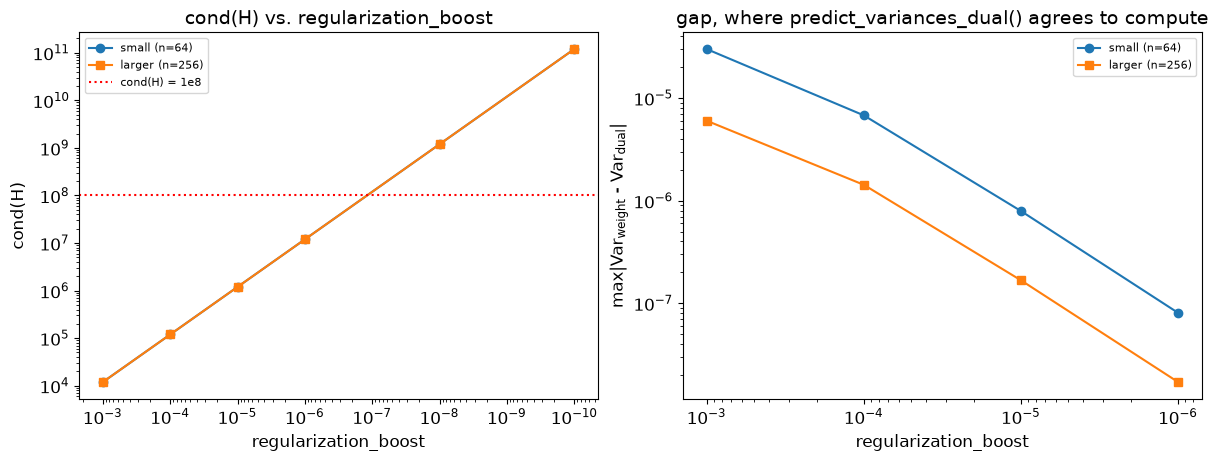

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for label, marker, color in [("small (n=64)", "o", "tab:blue"), ("larger (n=256)", "s", "tab:orange")]:
    sub = test3_df.loc[label]
    axs[0].loglog(sub.index, sub["cond(H)"], marker + "-", color=color, label=label)
    agree = sub[sub["status"] == "agrees"]
    axs[1].loglog(agree.index, agree["max|var_ws - var_dual|"], marker + "-", color=color, label=label)

axs[0].axhline(COND_SUSPECT_LINE, color="red", ls=":", label="cond(H) = 1e8")
axs[0].invert_xaxis(); axs[0].set_xlabel("regularization_boost"); axs[0].set_ylabel("cond(H)")
axs[0].set_title("cond(H) vs. regularization_boost"); axs[0].legend(fontsize=8)

axs[1].invert_xaxis(); axs[1].set_xlabel("regularization_boost")
axs[1].set_ylabel(r"max|Var$_{\mathrm{weight}}$ - Var$_{\mathrm{dual}}$|")
axs[1].set_title("gap, where predict_variances_dual() agrees to compute"); axs[1].legend(fontsize=8)
plt.show()

**Confirmed: `predict_variances_dual()` declines to compute exactly
where Test 1's `cond(H)` numbers say it should, and agrees with the
weight-space route once it proceeds, on both dataset sizes.**

At `regularization_boost=1e-10` and `1e-8` (`cond(H)=1.19e11`/`1.19e9`,
both above the `1e8` line), the method raises rather than returning a
number. At `1e-6` (`cond(H)=1.19e7`, just under the line), it agrees with
the weight route to `8.07e-8`/`1.71e-8` (small/larger dataset). **The gap
does not keep shrinking as `regularization_boost` grows further -- it
grows**, to `7.92e-7`/`1.67e-7` at `1e-5`, `6.78e-6`/`1.43e-6` at `1e-4`,
and `3.00e-5`/`6.01e-6` at `1e-3`. This is a genuine accuracy-vs-safety
trade-off, not noise: the boosted sibling model `predict_variances_dual()`
builds internally has its own `regularization_weight` set to
`regularization_boost`, so a larger boost buys a safer `cond(H)` at the
cost of fitting a sibling whose `H` is further from the original model's
-- the smallest gap sits right where the guard first allows the
computation to proceed, not at the largest `regularization_boost`
tested.

### Visual confirmation: the two routes' bands, overlaid

A visual check of Test 3's numeric agreement, at more than one slice and
in both directions: both routes share the same fitted mean (RMTB has one
mean surface regardless of which route computes its variance), with
$\pm2\sigma$ bands from `predict_variances()` and
`predict_variances_dual()` at `regularization_boost=1e-6` (`cond(H)`
safely under the `1e8` line), alongside the training data. Top row: fixed
$x_2$, swept along $x_1$. Bottom row: the orthogonal direction, fixed
$x_1$, swept along $x_2$.

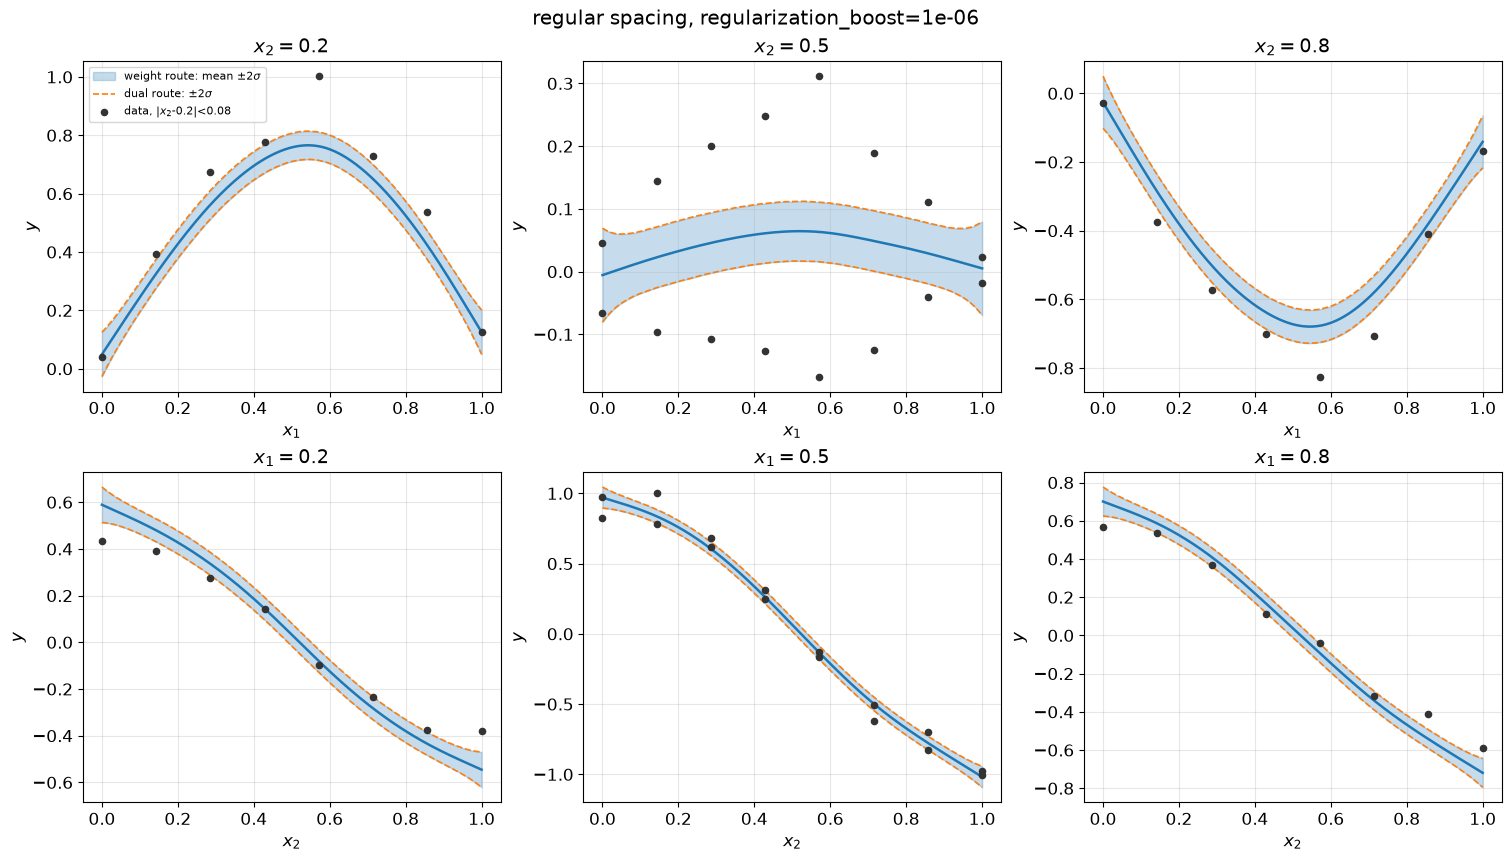

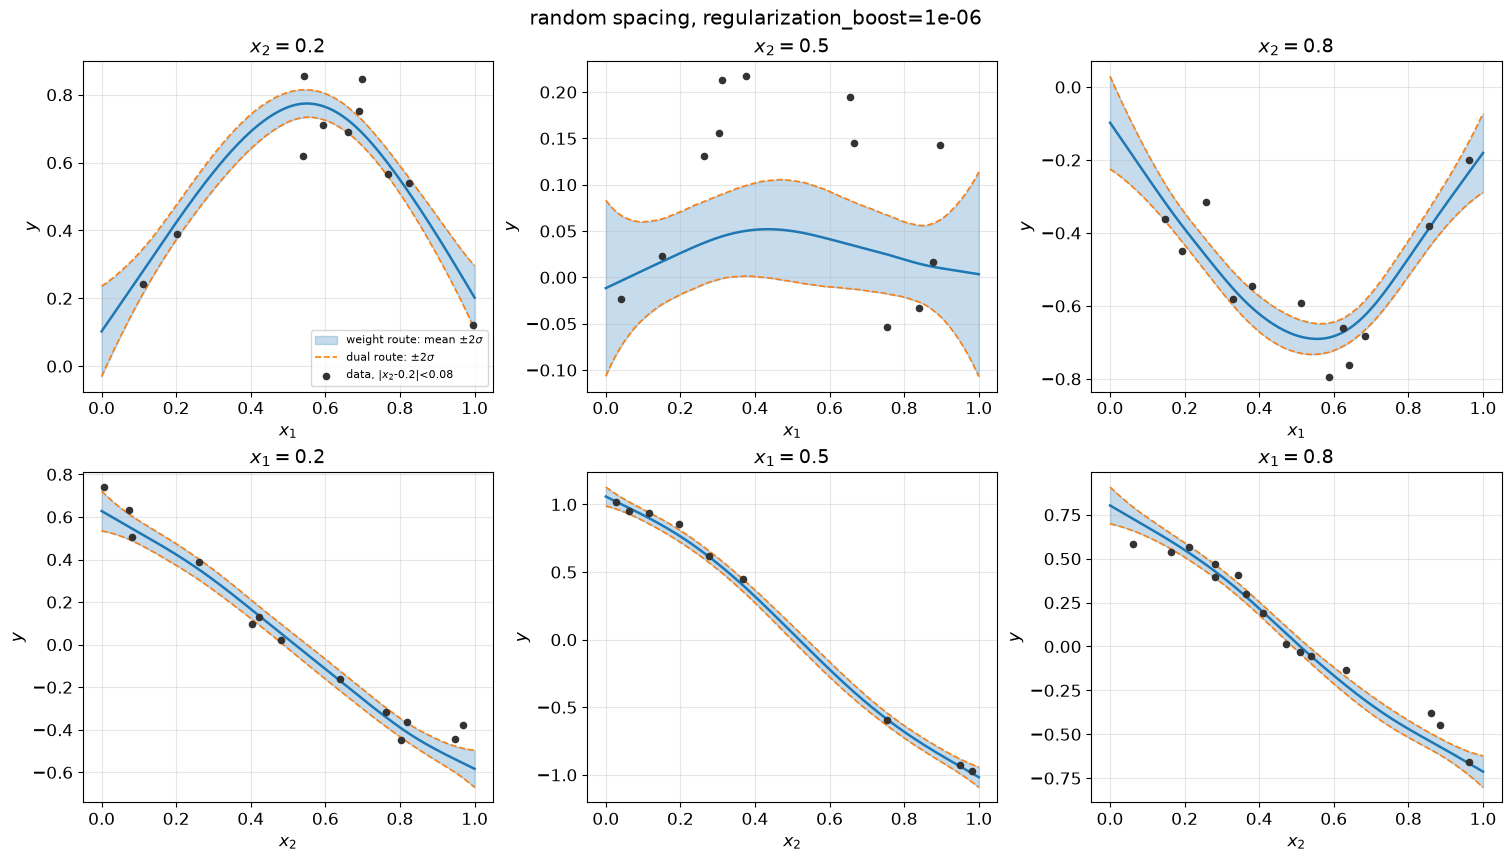

In [8]:
slice_values_viz = [0.2, 0.5, 0.8]
xq1d_viz = np.linspace(0, 1, 300)
near_tol_viz = 0.08
regularization_boost_viz = 1e-6


def band_panel(ax, xq, mean_viz, std_ws, std_dual, data_x, data_y, near, label_prefix):
    ax.fill_between(xq, mean_viz - 2 * std_ws, mean_viz + 2 * std_ws,
                     color="tab:blue", alpha=0.25, label=r"weight route: mean $\pm2\sigma$")
    ax.plot(xq, mean_viz - 2 * std_dual, color="tab:orange", lw=1.2, ls="--",
            label=r"dual route: $\pm2\sigma$")
    ax.plot(xq, mean_viz + 2 * std_dual, color="tab:orange", lw=1.2, ls="--")
    ax.plot(xq, mean_viz, color="tab:blue", lw=1.8)
    ax.scatter(data_x[near], data_y[near], s=20, color="0.2", zorder=5,
               label=f"data, {label_prefix}<{near_tol_viz}")


for spacing in models:
    X_viz, y_viz = datasets[spacing]
    m_viz = models[spacing]
    fig, axs = plt.subplots(2, 3, figsize=(15, 8.5), constrained_layout=True)

    for col, x2_fixed in enumerate(slice_values_viz):
        near = np.abs(X_viz[:, 1] - x2_fixed) < near_tol_viz
        Xq_line = np.column_stack([xq1d_viz, np.full_like(xq1d_viz, x2_fixed)])
        mean_viz = m_viz.predict_values(Xq_line).ravel()
        var_ws = m_viz.predict_variances(Xq_line)
        var_dual = m_viz.predict_variances_dual(Xq_line, regularization_boost=regularization_boost_viz)
        std_ws = np.sqrt(np.clip(var_ws, 0.0, None))
        std_dual = np.sqrt(np.clip(var_dual, 0.0, None))
        band_panel(axs[0, col], xq1d_viz, mean_viz, std_ws, std_dual, X_viz[:, 0], y_viz, near,
                   f"|$x_2$-{x2_fixed}|")
        axs[0, col].set_title(f"$x_2={x2_fixed}$")
        axs[0, col].set_xlabel("$x_1$"); axs[0, col].set_ylabel("$y$"); axs[0, col].grid(alpha=0.3)

    for col, x1_fixed in enumerate(slice_values_viz):
        near = np.abs(X_viz[:, 0] - x1_fixed) < near_tol_viz
        Xq_line = np.column_stack([np.full_like(xq1d_viz, x1_fixed), xq1d_viz])
        mean_viz = m_viz.predict_values(Xq_line).ravel()
        var_ws = m_viz.predict_variances(Xq_line)
        var_dual = m_viz.predict_variances_dual(Xq_line, regularization_boost=regularization_boost_viz)
        std_ws = np.sqrt(np.clip(var_ws, 0.0, None))
        std_dual = np.sqrt(np.clip(var_dual, 0.0, None))
        band_panel(axs[1, col], xq1d_viz, mean_viz, std_ws, std_dual, X_viz[:, 1], y_viz, near,
                   f"|$x_1$-{x1_fixed}|")
        axs[1, col].set_title(f"$x_1={x1_fixed}$")
        axs[1, col].set_xlabel("$x_2$"); axs[1, col].set_ylabel("$y$"); axs[1, col].grid(alpha=0.3)

    axs[0, 0].legend(fontsize=8)
    fig.suptitle(f"{spacing} spacing, regularization_boost={regularization_boost_viz:.0e}")
    plt.show()

**Confirmed visually, at all six slices per spacing and in both
directions: the dual route's dashed band sits on the weight route's
filled band everywhere**, indistinguishable by eye -- the picture-level
version of Test 3's `8.07e-8`/`1.71e-8` gap at this same
`regularization_boost`. Bands widen where fewer training points sit near
the slice (visible at $x_2=0.5$ on both spacings, the sparsest row/
column of the two directions tested) and narrow where more do, in both
directions equally -- the same proximity-driven behavior in whichever
axis is held fixed, not a direction-specific artifact.

## Conclusion

### What was tested and proved

- **`H` is not just ill-conditioned but exactly rank-deficient in a
  structurally meaningful way, and that rank deficiency does not depend
  on the training data**: its near-zero eigenvalues sit at the
  `regularization_weight` floor and span, to a `7.46e-14` mean relative
  residual, the bilinear trend $\{1,x_1,x_2,x_1x_2\}$ -- the direct
  consequence of RMTB's additive per-axis energy penalty, identical for
  regular and random spacing because `H` never depends on $X$ or $y$
  (Test 1).
- **Shrinking `num_ctrl_pts` does not fix it, in either direction**:
  `cond(H)` never drops below `6.15e11` even at the smallest usable
  basis, and gets worse, not better, as `num_ctrl_pts` grows -- ruling
  out "too many parameters" as the explanation, and ruling out "too few"
  as a fix (Test 2).
- **`RMTBUQ.predict_variances_dual()` agrees with the weight-space route**
  once `regularization_boost` is raised enough to bring `cond(H)` under
  the `1e8` safety line -- confirmed at two dataset sizes (`n=64`,
  `n=256`), both numerically and visually, with its own guard declining
  to compute exactly where Tests 1-2's `cond(H)` numbers predict it
  should (Test 3).
- **Past that line, agreement does not keep improving with a larger
  `regularization_boost` -- it gets worse**: the smallest gap to the
  weight-space route sits right where the guard first allows computation
  (`8.07e-8`/`1.71e-8` at `regularization_boost=1e-6`), and grows by two
  orders of magnitude by `1e-3` (`3.00e-5`/`6.01e-6`), because a larger
  boost fits a sibling model whose `H` is further from the original
  model's (Test 3).

### Other important observations

- **The null-space dimension is not perfectly clean at the smallest
  practical resolution** (`8` near-zero eigenvalues at `num_ctrl_pts=4`,
  not `4`), reported in Test 2 rather than smoothed over, though this
  notebook does not characterize what the extra directions are. It
  settles to exactly `4`, matching Test 1, from `num_ctrl_pts=6` onward.
- **`cond(H)`'s independence from the training data is a useful property
  for anyone tuning RMTB**: since it depends only on
  `num_ctrl_pts`/`order`/`energy_weight`/`regularization_weight`/`xlimits`,
  it can be checked once per configuration and trusted across any dataset
  that configuration will be used on -- unlike `cond(mtx)`, which does
  depend on the data and needs checking per dataset.

### Recommendation

**`RMTBUQ.predict_variances()` -- the weight-space route -- remains the
recommended default for RMTB's variance estimate.** This notebook
provides the structurally independent confirmation Section 1.2 argued
for: Proposition 6's dual-route identity, as implemented in
`predict_variances_dual()`, is confirmed directly for a
regularization-boosted variant of RMTB, in both a small and a larger
synthetic dataset. The remaining gap is a
bordered-system-style construction that would make the dual route safe
at RMTB's literal default settings -- unfinished work, not attempted
here. `predict_variances_dual()`'s `cond(H)>1e8` guard rail, and its
narrowing-then-widening gap past that line, together argue for using its
default `regularization_boost` rather than pushing it higher for
"extra safety." The real-data stress test, where these synthetic-data
conclusions are checked against a harder case, is deferred to
Notebook 7.